# Sprint 1 – Spotify Genre Classifier

**Goal:** predict the genre of a song from its features.

**Workflow of this notebook:**
1. Setup
2. Load the data and take a first look
3. Exploratory Data Analysis (EDA) and cleaning
4. Train / validation / test split
5. Preprocessing
6. Models (3 model families) + cross-validation
7. Hyperparameter tuning
8. Evaluation (metrics, confusion matrices)
9. Feature importance + retraining on the best features
10. Conclusion and discussion

## Big Picture View:

Slides call this **supervised learning**: the data contains the correct answer, or **ground truth**.

| Component | Name | Examples | Role |
|---|---|---|---|
| **X** | Features | `danceability`, `tempo`, `energy`, `acousticness` | Input clues used by the model |
| **y** | Target / label | `genre` | Correct answer the model learns to predict |

The model only gets X, and it predicts the genre. That's the whole goal. 

## 1. Setup

Libs

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

## 2. First look 

Whats in the csv

In [12]:
DATA_PATH = "data/Spotify_tracks_final.csv"
df = pd.read_csv(DATA_PATH, index_col=0)  
# df stands for DataFrame (2-dimensional labeled data structure with columns of potentially different types)

In [6]:
print(df.shape)

(2112746, 29)


In [7]:
df.head()

,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71ca4ea95503e...,ambient,0.990,0.184,0.03270,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9c848708316...,ambient,0.985,0.250,0.01480,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd955c89d480...,ambient,0.993,0.269,0.02110,0.883,5,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da62792f8277...,ambient,0.995,0.230,0.13800,0.885,4,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979ca20bbd759...,ambient,0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 2112746 entries, 0 to 3924134
Data columns (total 29 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   track_name                    str    
 1   track_id                      str    
 2   album_name                    str    
 3   album_id                      str    
 4   album_image                   str    
 5   album_release_date            str    
 6   album_release_date_precision  str    
 7   artist_name                   str    
 8   artist_id                     str    
 9   popularity                    int64  
 10  duration_ms                   int64  
 11  explicit                      bool   
 12  preview_url                   str    
 13  genre                         str    
 14  acousticness                  float64
 15  danceability                  float64
 16  energy                        float64
 17  instrumentalness              float64
 18  key                           int64  


### What the columns mean

| Group | Columns | Meaning |
|---|---|---|
| IDs and links | `track_id`, `album_id`, `artist_id`, `album_image`, `preview_url`, `database_shard_id` | Technical codes. They do not describe the sound. |
| Text | `track_name`, `album_name`, `artist_name` | Names of the song, album and artist |
| Release | `album_release_date`, `album_release_date_precision` | When the album came out (day, month or only year) |
| Popularity | `popularity`, `explicit` | 0–100 popularity score; explicit lyrics yes/no |
| Length | `duration_ms`, `duration_seconds`, `duration_minutes` | The same length in 3 units |
| Audio features (0–1) | `acousticness`, `danceability`, `energy`, `instrumentalness`, `liveness`, `speechiness`, `valence` | Spotify's scores of how the song sounds |
| Musical features | `key`, `mode`, `tempo`, `time_signature`, `loudness` | Musical key, major/minor, speed (BPM), beats per bar, volume (dB) |
| **Target** | `genre` | The label we want to predict (113 genres) |

## 3. Exploratory Data Analysis (EDA) and cleaning

**Goal:** understand the data and find problems *before* we train any model.

We check:
1. Missing values
2. Duplicates
3. The target: how many songs per genre?
4. Summary statistics of the numeric columns
5. Strange or impossible values

### 3.1 Missing values

value of 0 means that column has no missing values (NaN).

In [9]:
df.isna().sum()

track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature                       0
valence                  

### 3.2 Duplicates

The same song twice would let the model 'cheat' if one copy ends up in training and the other in testing.

Duplicate songs can cause data leakage: if the same song appears in both the training and testing datasets, the model may recognize a song it has already seen instead of learning general patterns.

In [10]:
print("Duplicate track_ids:", df.duplicated(subset="track_id").sum()) #count duplicate track_ids
print("Duplicate name + artist:", df.duplicated(subset=["track_name", "artist_name"]).sum()) # count duplicate track_name + artist_name combinations

Duplicate track_ids: 0
Duplicate name + artist: 0


### 3.3 The target: songs per genre 

target = goal

count      113.000000
mean     18696.867257
std      10558.148703
min         66.000000
25%      10232.000000
50%      17606.000000
75%      25597.000000
max      48143.000000
Name: count, dtype: float64
Amount of genres: 113


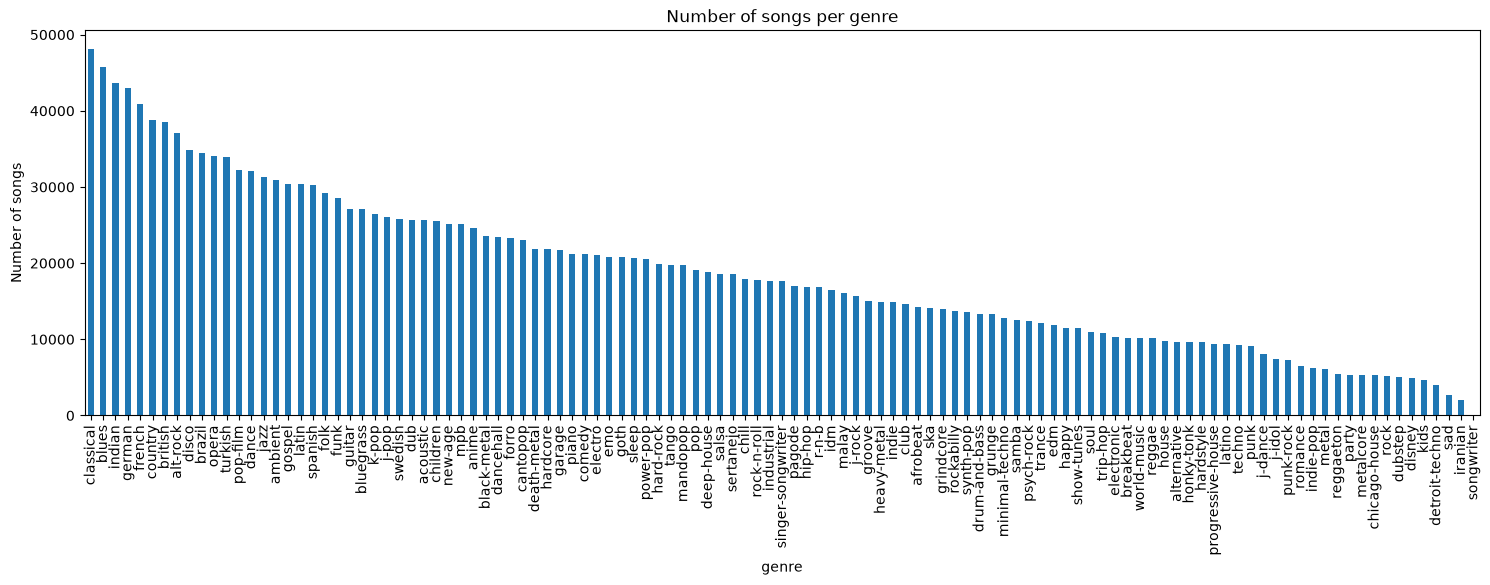

In [14]:
genre_counts = df["genre"].value_counts()
print(genre_counts.describe())
print("Amount of genres:", len(genre_counts))

plt.figure(figsize=(18, 5))
genre_counts.plot(kind="bar")
plt.title("Number of songs per genre")
plt.ylabel("Number of songs")
plt.show()

Data is imbalanced -> some genres have far more songs than others -> A model might learn to predict the larger genres better than the smaller ones.
 
This is important to consider when choosing evaluation metrics and splitting your data into training and testing sets.

### 3.4 Summary statistics

In [15]:
df.describe().T #shows a summary of the main features, statistics for the numerical columns in dataset

,count,mean,std,min,25%,50%,75%,max
popularity,2112746.0,13.776745,14.636743,0.00000,1.000000,9.000000,22.0000,1.000000e+02
duration_ms,2112746.0,249433.419220,145301.745654,486.00000,179501.000000,226886.500000,287880.0000,7.200006e+06
acousticness,2112746.0,0.392193,0.366965,0.00000,0.022100,0.289000,0.7600,9.960000e-01
danceability,2112746.0,0.528538,0.179740,0.00000,0.404000,0.539000,0.6630,9.950000e-01
energy,2112746.0,0.583389,0.275947,0.00002,0.370000,0.613000,0.8260,1.000000e+00
instrumentalness,2112746.0,0.218848,0.346954,0.00000,0.000001,0.000826,0.4060,1.000000e+00
key,2112746.0,5.248916,3.532847,0.00000,2.000000,5.000000,8.0000,1.100000e+01
liveness,2112746.0,0.224510,0.202518,0.00296,0.097700,0.137000,0.2910,1.000000e+00
loudness,2112746.0,-10.252837,5.799937,-58.10000,-12.901000,-8.900000,-6.1170,6.172000e+00
mode,2112746.0,0.662071,0.473004,0.00000,0.000000,1.000000,1.0000,1.000000e+00


| Column | Meaning |
|---|---|
| `count` | Number of non-missing values. |
| `mean` | Average value. |
| `std` | Standard deviation: how much values vary around the mean. |
| `min` | Smallest value. |
| `25%` | First quartile: 25% of values are at or below this value. |
| `50%` | Median: half the values are at or below this value. |
| `75%` | Third quartile: 75% of values are at or below this value. |
| `max` | Largest value. |

### 3.5 Unsual values

values that may be invalid or unusual in the dataset

In [16]:
print("tempo = 0:", (df["tempo"] == 0).sum())
print("time_signature = 0:", (df["time_signature"] == 0).sum())
print("shorter than 30 s:", (df["duration_ms"] < 30_000).sum())
print("longer than 20 min:", (df["duration_ms"] > 20 * 60_000).sum())
print("loudness > 0 dB:", (df["loudness"] > 0).sum())
print("popularity = 0:", (df["popularity"] == 0).sum())

tempo = 0: 2
time_signature = 0: 64
shorter than 30 s: 3640
longer than 20 min: 5071
loudness > 0 dB: 1207
popularity = 0: 426374


| Check | Count | Interpretation |
|---|---:|---|
| Tempo = 0 | 2 | Likely invalid tempo values |
| Time signature = 0 | 64 | Possibly missing or invalid data |
| Duration < 30 seconds | 3,640 | Short clips or incomplete tracks |
| Duration > 20 minutes | 5,071 | Unusually long tracks |
| Loudness > 0 dB | 1,207 | Unusual values worth checking |
| Popularity = 0 | 426,374 | Tracks with no recorded popularity |

### Data Observations so far

*(Rewrite these in your own words.)*

- Almost no missing values: only a few names are missing. Names are not used as features, so this is not a problem.
- No duplicate songs.
- The genres are **unbalanced**: from about 48,000 songs (classical) down to 66 (songwriter).
- Some values are strange: tempo 0, time signature 0, very short or very long tracks.
- 20% of songs have popularity 0.